# Convolutional Neural Network for Telling Professional Models from Common People

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

A modelling agency receives thousands of portraits from people who want to be
represented, and a casting team spends hours sorting them. The question here is a
first filter for that pile: given a close-up photograph of a face, does it look
like the portrait of a professional model or like the photograph of a common
person. People make that call at a glance, but nobody can write it down as a rule
made of pixel values, so it is a job for a model fitted on examples.

What separates the two groups is not one obvious object, as a mask would be. It
is a mix of the face itself and of the way the picture was taken: lighting,
make-up, pose, sharpness and colour. A model trained on these photographs will
use whatever separates them, and part of the work in this notebook is to find
out which of those things it is actually using.

A convolutional neural network, CNN for short, is built for this kind of input.
Instead of connecting every neuron to every pixel, it slides small grids of
weights called filters, or kernels, over the picture. Each filter produces a
feature map, a new image whose cells say how strongly the pattern of that filter
appears in each zone. The first layers learn simple patterns such as edges and
patches of colour, and the later ones combine them into larger shapes such as an
eye, an eyebrow or the outline of the lips. That ladder from small details to
whole shapes is called the feature hierarchy, and it means nobody has to decide
by hand which measurements describe a face. The network learns them from the
photographs.

The task is a binary classification. The response is the group of the
photograph, professional model or common person, and the predictors are the
pixels themselves. The model is judged on photographs it never saw during
training, by its accuracy and by the two kinds of mistake it makes: passing a
common person as a model, and discarding a model as a common person.

### Libraries

In [1]:
# Files, timing and dataset download
import os
import time
import zipfile
import importlib.util
import urllib.request

# Keras runs on TensorFlow when it is installed, as in Google Colab. On a machine
# without TensorFlow the same code runs on PyTorch instead. The backend has to be
# chosen before keras is imported
if importlib.util.find_spec('tensorflow') is None and not os.environ.get('KERAS_BACKEND'):
    os.environ['KERAS_BACKEND'] = 'torch'

# Data handling
import numpy as np
import pandas as pd

# Reading the photographs
from PIL import Image

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# The neural network
import keras
from keras import layers

# Evaluation
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score)

# Where the data comes from and where it lands. In Colab the working folder is
# /content, and on a local machine it is the folder of the notebook
DATASET_URL = ('https://gitlab.com/ejimenez/beauty/-/raw/main/'
               'beauty.zip?inline=false')
ZIP_NAME = 'beauty.zip'
DATA_DIR = 'beauty'
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png')

# The dataset arrives already split in three folders, and each one holds one
# folder per class. The positive class, the one every recall and the ROC curve
# refer to, is the professional model
SPLITS = ['train', 'valid', 'test']
CLASS_FOLDERS = {'average': 0, 'beautiful': 1}
CLASS_NAMES = ['common person', 'professional model']
CLASS_COLOURS = ['#4c72b0', '#c44e52']

# Every photograph is read at LOAD_SIZE, in colour, and the network receives a
# crop of IMAGE_SIZE taken from it: a random one during training and the
# central one everywhere else
LOAD_SIZE = (128, 128)
IMAGE_SIZE = (112, 112)
CHANNELS = 3
PIXEL_MAX = 255.0
FLIP_CHANCE = 0.5

# Training settings
BATCH_SIZE = 32
EPOCHS = 30
DROPOUT_RATE = 0.5

# Step size of the Adam optimizer, the value Keras uses by default
LEARNING_RATE = 0.001

# The network returns logits, so accuracy compares them with 0, the logit of a
# probability of 0.5. The plain 'accuracy' metric would compare them with 0.5
LOGIT_THRESHOLD = 0.0

# Where the weights of the best epoch and the final network are saved
CHECKPOINT_FILE = 'beauty_cnn_best.weights.h5'
MODEL_FILE = 'beauty_cnn.keras'

# Fixed so every run gives the same crops, flips and starting weights
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

sns.set_style('whitegrid')
print('Keras', keras.__version__, 'running on', keras.backend.backend())

Keras 3.13.2 running on tensorflow


## Data Understanding (CRISP-DM 2)

The dataset is a zip with three folders, train, valid and test, and inside each
one a folder per class: beautiful for the portraits of professional models and
average for the photographs of common people. The folder a photograph sits in is
its label, so there is no annotation file to join and no photograph without a
response. The cell below downloads and unpacks the zip only when the folder is
not already next to the notebook, so the same cell works in Colab and on a local
machine.

In [2]:
# The dataset is fetched only when it is not already on disk. If the folder is
# there the cell does nothing, if only the zip is there it is unpacked, and if
# neither exists the zip is downloaded first
if os.path.isdir(DATA_DIR):
    print('The folder', DATA_DIR, 'is already present, nothing is downloaded.')
else:
    if os.path.exists(ZIP_NAME):
        print('The zip is already here, only unpacking is needed.')
    else:
        print('Downloading the dataset...')
        start = time.time()
        urllib.request.urlretrieve(DATASET_URL, ZIP_NAME)
        print('Downloaded %.1f MB in %.1f seconds.'
              % (os.path.getsize(ZIP_NAME) / 1024 ** 2, time.time() - start))
    with zipfile.ZipFile(ZIP_NAME) as archive:
        archive.extractall('.')
    print('Unpacked into', DATA_DIR)

for split in SPLITS:
    print('Folders inside', os.path.join(DATA_DIR, split) + ':',
          sorted(os.listdir(os.path.join(DATA_DIR, split))))

Downloaded 67.1 MB in 0.8 seconds.
Unpacked into beauty
Folders inside beauty/train: ['average', 'beautiful']
Folders inside beauty/valid: ['average', 'beautiful']
Folders inside beauty/test: ['average', 'beautiful']


The message printed says which of the three situations the cell found: the folder
already unpacked, the zip present but not unpacked, or neither, in which case it
downloaded the file. The listing at the end confirms that each of the three parts
holds the two folders that carry the labels.

Photographs in total: 4600

folder  average  beautiful  total  model %
split                                     
train      2000       2000   4000     50.0
valid       150        150    300     50.0
test        150        150    300     50.0


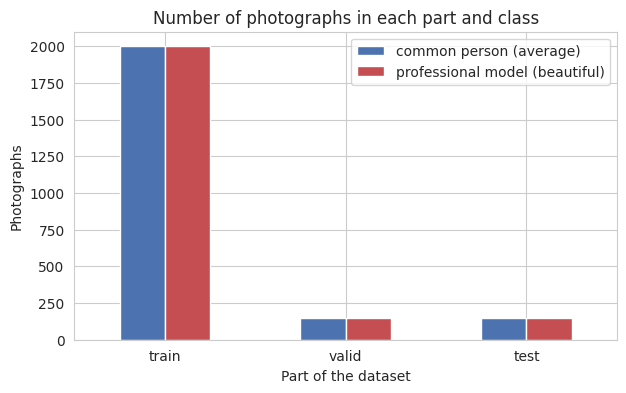

In [3]:
# One row per photograph, with the part it belongs to and the label its folder gives
records = []
for split in SPLITS:
    for folder, label in CLASS_FOLDERS.items():
        folder_path = os.path.join(DATA_DIR, split, folder)
        for name in sorted(os.listdir(folder_path)):
            if name.lower().endswith(IMAGE_EXTENSIONS):
                records.append({'path': os.path.join(folder_path, name),
                                'split': split,
                                'folder': folder,
                                'label': label})

faces = pd.DataFrame(records)
print('Photographs in total:', len(faces))
print()
counts = pd.crosstab(faces['split'], faces['folder']).reindex(SPLITS)
counts['total'] = counts.sum(axis=1)
counts['model %'] = (100 * counts['beautiful'] / counts['total']).round(1)
print(counts)

# Photographs per part, one bar per class
counts[list(CLASS_FOLDERS)].plot.bar(figsize=(7, 4), color=CLASS_COLOURS, rot=0)
plt.title('Number of photographs in each part and class')
plt.xlabel('Part of the dataset')
plt.ylabel('Photographs')
plt.legend([CLASS_NAMES[0] + ' (average)', CLASS_NAMES[1] + ' (beautiful)'])
plt.show()

The table gives, for each of the three parts, how many photographs each class
holds, the total and the share of professional models, and the bar chart draws
the same counts side by side.

The collection holds 4600 photographs and every part is perfectly balanced: 2000
of each class for training and 150 of each for validation and for test. A model
that ignored the picture and always gave the same answer would be right exactly
half the time, and that is the floor every later result has to clear. With the
classes this even, accuracy is a fair summary of the problem. The cost of the
split is that validation and test are small, 300 photographs each, so a single
photograph moves their accuracy by a third of a percentage point.

In [4]:
# Size and colour mode of every file, read from the header only
sizes, modes = [], []
for path in faces['path']:
    with Image.open(path) as handle:
        sizes.append('%d x %d' % handle.size)
        modes.append(handle.mode)
faces['size'] = sizes
faces['mode'] = modes
print('Sizes found:')
print(faces['size'].value_counts())
print()
print('Colour modes found:')
print(faces['mode'].value_counts())

Sizes found:
size
224 x 224    4600
Name: count, dtype: int64

Colour modes found:
mode
RGB    4600
Name: count, dtype: int64


The first list counts the different sizes of the files, written as width by
height in pixels, and the second counts the colour modes. RGB is a colour image
with three channels, one matrix each for red, green and blue, and any other mode
would have to be converted before the photograph enters the network.

Every one of the 4600 files is a 224 by 224 RGB picture, so nothing has to be
converted and no file stands out by its size. The collection was clearly
prepared beforehand, with each face already cut out and centred in a square.

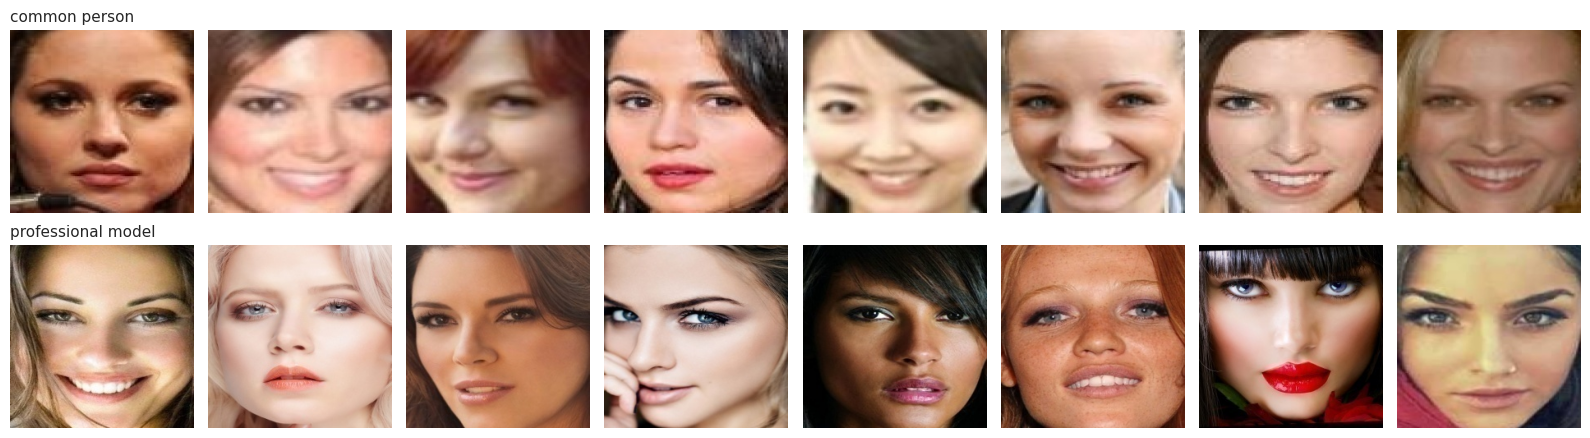

In [5]:
# Eight training photographs of each class, straight from the files
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
train_faces = faces[faces['split'] == 'train']
for row, folder in enumerate(CLASS_FOLDERS):
    chosen = train_faces[train_faces['folder'] == folder].sample(8, random_state=RANDOM_STATE)
    for ax, path in zip(axes[row], chosen['path']):
        with Image.open(path) as handle:
            ax.imshow(handle.convert('RGB'))
        ax.axis('off')
    axes[row][0].set_title(CLASS_NAMES[CLASS_FOLDERS[folder]], loc='left', fontsize=11)
plt.tight_layout()
plt.show()

The grid shows eight training photographs of each class exactly as they sit in
the files, the common people in the top row and the professional models in the
bottom row.

Both rows are close-ups of women looking at the camera, cropped from the forehead
to the chin, so framing alone does not tell the classes apart. Still, the rows do
not look alike. The models wear visible make-up, eyeliner and lipstick, are lit
evenly and come out sharp, while several common people are blurred or caught
mid smile in what look like everyday snapshots. Some of what
separates the classes is therefore the face and some is the way the photograph
was taken, and the network will see both.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

A CNN needs every input to have the same shape, so each photograph is converted
to colour and resized to 128 by 128 pixels, a little larger than the 112 by 112
the network receives, so there is room to cut a crop out of it later. The result
is a tensor, a table of numbers with any number of dimensions. One photograph
becomes a tensor of 128 x 128 x 3, a stack of three matrices, one per colour
channel, and each part of the dataset becomes a tensor of four dimensions:
photographs, height, width and channels. The pixels are kept as whole numbers
from 0 to 255 to save memory, and are divided by 255 only when a batch is handed
to the network.

In [6]:
# One photograph becomes a 128 x 128 colour array of whole numbers from 0 to 255
def load_image(path):
    """Read a file as an RGB array of LOAD_SIZE."""
    with Image.open(path) as handle:
        resized = handle.convert('RGB').resize(LOAD_SIZE, Image.BILINEAR)
    return np.asarray(resized, dtype=np.uint8)


# Every photograph of the three parts is read, none is left out
start = time.time()
images = np.empty((len(faces), LOAD_SIZE[1], LOAD_SIZE[0], CHANNELS), dtype=np.uint8)
for position, path in enumerate(faces['path']):
    images[position] = load_image(path)
labels = faces['label'].to_numpy(dtype=np.int8)

# The split comes with the dataset and is kept as it is
in_part = {split: (faces['split'] == split).to_numpy() for split in SPLITS}
x_train, y_train = images[in_part['train']], labels[in_part['train']]
x_valid, y_valid = images[in_part['valid']], labels[in_part['valid']]
x_test, y_test = images[in_part['test']], labels[in_part['test']]

print('Read %d photographs in %.1f seconds.' % (len(images), time.time() - start))
for name, x, y in [('train', x_train, y_train), ('valid', x_valid, y_valid),
                   ('test', x_test, y_test)]:
    print('%-6s images %s   labels %s' % (name, x.shape, y.shape))
print('Memory used by the images: %.1f MB' % (images.nbytes / 1024 ** 2))

Read 4600 photographs in 7.5 seconds.
train  images (4000, 128, 128, 3)   labels (4000,)
valid  images (300, 128, 128, 3)   labels (300,)
test   images (300, 128, 128, 3)   labels (300,)
Memory used by the images: 215.6 MB


The shape of each image tensor reads as photographs, height, width and channels,
which is the order Keras expects, and each label vector holds one 0 or 1 per
photograph, 0 for a common person and 1 for a professional model.

The three parts are used as the dataset delivers them, and none of them is
shuffled into another. The training part is what the network learns from. The
validation part is measured after every epoch, one full pass over the training
photographs, to watch whether the network keeps improving on pictures it does
not learn from. The test part is used once, at the end, to report the final
result.

The training part holds 4000 photographs and validation and test 300 each, all
of 128 by 128 pixels with 3 channels. Stored as whole numbers from 0 to 255 the
whole collection takes 215.6 MB of memory, so every photograph is kept and none
had to be left out to fit.

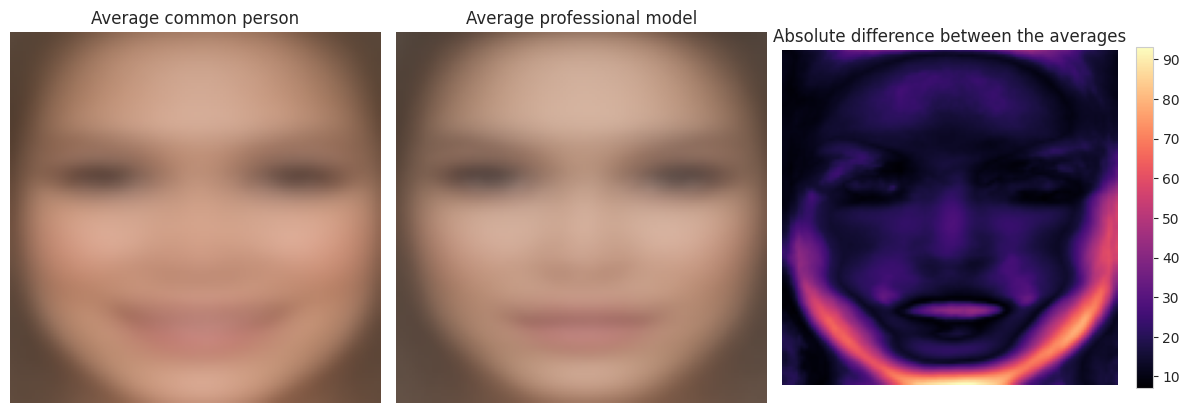

In [7]:
# The average photograph of each class, pixel by pixel, over the training part
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
means = {}
for ax, label in zip(axes, [0, 1]):
    means[label] = x_train[y_train == label].mean(axis=0)
    ax.imshow(means[label].astype(np.uint8))
    ax.set_title('Average ' + CLASS_NAMES[label])
    ax.axis('off')

# Where the two averages differ the most, summed over the three channels
difference = np.abs(means[1] - means[0]).sum(axis=2)
shown = axes[2].imshow(difference, cmap='magma')
axes[2].set_title('Absolute difference between the averages')
axes[2].axis('off')
fig.colorbar(shown, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

The first two panels are the average photograph of each class: every pixel is
the mean of that pixel over all the training photographs of the class, so
whatever sits in the same place in most pictures stays sharp and whatever moves
around blurs away. The third panel shows, for each pixel, how far apart the two
averages are, with dark meaning the classes look the same there and bright
meaning they differ. The scale on its right is out of the 765 that would
separate pure black from pure white on all three channels.

Both averages show a face centred in the frame, with the eyes at the same height,
which confirms the crops were aligned the same way for both classes. The
difference map runs from about 7 to 93. The eyes are among the darkest zones,
near 14 on average, because both classes have them in the same place. The
brightest zone, at the maximum of 93, is the bottom edge of the frame below the
chin, and a bright arc follows both sides of the jaw, around 40 at the height of
the mouth. The average model has a narrower face that ends before the bottom of
the frame, while the average common person still fills it with cheek and chin.
So the clearest difference between the averages is the outline of the face, not
the eyes or the skin tone, and that outline depends both on the person and on
how tightly each picture was cropped.

                    brightness  saturation   sharpness
class                                                 
common person       134.100006        64.0   80.300003
professional model  131.399994        54.5  212.699997


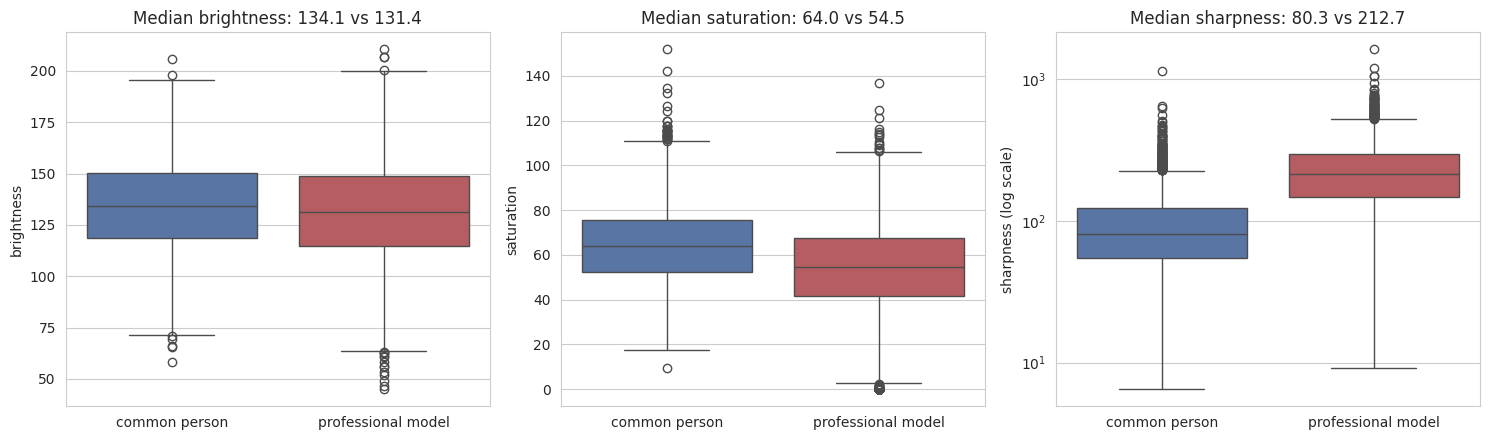

In [8]:
# Three traits of the picture rather than of the face, measured on every photograph
def picture_traits(image):
    """Return brightness, colour saturation and sharpness of one RGB array."""
    pixels = image.astype(np.float32)
    grey = pixels.mean(axis=2)
    brightness = grey.mean()
    # Saturation: how far the strongest channel is from the weakest, 0 for grey
    saturation = (pixels.max(axis=2) - pixels.min(axis=2)).mean()
    # Sharpness: spread of the Laplacian, which is large where edges are crisp
    laplacian = (4 * grey[1:-1, 1:-1] - grey[:-2, 1:-1] - grey[2:, 1:-1]
                 - grey[1:-1, :-2] - grey[1:-1, 2:])
    return brightness, saturation, laplacian.var()


traits = pd.DataFrame([picture_traits(image) for image in images],
                      columns=['brightness', 'saturation', 'sharpness'])
traits['class'] = [CLASS_NAMES[label] for label in labels]
print(traits.groupby('class').median().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, trait in zip(axes, ['brightness', 'saturation', 'sharpness']):
    sns.boxplot(data=traits, x='class', y=trait, hue='class', ax=ax,
                palette=CLASS_COLOURS, legend=False)
    ax.set_title('Median %s: %.1f vs %.1f'
                 % (trait, *traits.groupby('class')[trait].median().reindex(CLASS_NAMES)))
    ax.set_xlabel('')
axes[2].set_yscale('log')
axes[2].set_ylabel('sharpness (log scale)')
plt.tight_layout()
plt.show()

The three measures describe the picture, not the person. Brightness is the
average grey level from 0, black, to 255, white. Saturation is how far apart the
strongest and the weakest colour channel are, on average, which is 0 for a grey
picture and grows with vivid colour. Sharpness is the spread of the Laplacian, a
filter that compares each pixel with its four neighbours, so it is large where
the edges are crisp and small where the picture is blurred. The table gives the
median of each measure per class, the value that leaves half the photographs
above and half below.

Each box plot draws the spread of one measure per class. The line inside the box
is the median, the box covers the middle half of the photographs, the whiskers
reach the photographs that are still close to the rest, and the dots beyond them
are the unusual ones. Two boxes at the same height mean the trait does not
separate the classes, and two boxes apart mean a network could tell the classes
apart by that trait alone, without looking at the face.

Brightness barely separates the classes, with medians of 134.1 for common people
and 131.4 for models and boxes that overlap almost entirely. Saturation separates
them a little, 64.0 against 54.5, so the model portraits have slightly softer
colour. Sharpness is the striking one. The median model photograph has a
sharpness of 212.7 against 80.3 for a common person, more than two and a half
times as much, and on the log scale the two boxes barely overlap. Professional
portraits are taken with good cameras and retouched, snapshots are not, and that
is a difference a network can exploit without learning anything about faces.

In [9]:
# How far the three picture traits alone go: a logistic regression on them,
# fitted on the training part and scored on the test part. Sharpness enters as
# its logarithm because its values span two orders of magnitude
trait_inputs = traits[['brightness', 'saturation']].assign(
    log_sharpness=np.log1p(traits['sharpness'])).to_numpy()
trait_model = make_pipeline(StandardScaler(), LogisticRegression())
trait_model.fit(trait_inputs[in_part['train']], y_train)
trait_test_predicted = trait_model.predict(trait_inputs[in_part['test']])
print('Test accuracy from the picture traits alone: %.4f'
      % accuracy_score(y_test, trait_test_predicted))
coefficients = trait_model[-1].coef_[0]
print(pd.Series(coefficients, index=['brightness', 'saturation', 'log sharpness'],
                name='coefficient on the standardised trait').round(3))

Test accuracy from the picture traits alone: 0.8333
brightness      -0.451
saturation      -0.388
log sharpness    1.928
Name: coefficient on the standardised trait, dtype: float64


The logistic regression is a classifier that knows nothing about faces. It only
sees the three numbers of each photograph, with sharpness on a logarithmic
scale, and each trait is standardised first, shifted and rescaled so that it
has mean 0 and standard deviation 1, which lets the three coefficients be
compared with each other. A positive coefficient pushes a photograph toward
professional model as the trait grows, a negative one toward common person, and
the larger its size the more that trait weighs. The accuracy printed is how often
that blind classifier is right on the test photographs, and it is the part of
the problem that can be solved without looking at anybody's face.

From brightness, saturation and sharpness alone the logistic regression is right
on 83.33 percent of the test photographs, far above the floor of 50 percent. The
coefficient of log sharpness, 1.928, is more than four times the size of the
other two, -0.451 for brightness and -0.388 for saturation, so sharpness does
nearly all the work: the sharper the picture, the more likely it is a model.
This is the number the CNN has to be compared with. A network that only matched
it would have learned the camera, not the face.

The training photographs get data augmentation. Every time a photograph enters a
batch it is slightly changed at random: a random 112 by 112 crop is cut out of
the 128 by 128 picture, which shifts the face a few pixels in any direction, and
the crop is flipped left to right half of the time. A face shifted or mirrored is
still the same person with the same label, so the network gets a new example for
free and has a harder time memorising single pictures. The changes happen only
during training. Validation and test photographs always get the central crop and
nothing random, so their scores can be compared from one epoch to the next.

In [10]:
# Turn a batch of stored photographs into network input. In training mode each
# photograph gets a random crop and a random horizontal flip, in eval mode the
# central crop. Both divide the pixels by 255
def preprocess(batch, mode='train'):
    """Crop, maybe flip and scale a batch of LOAD_SIZE photographs."""
    count = len(batch)
    room_y = LOAD_SIZE[1] - IMAGE_SIZE[1]
    room_x = LOAD_SIZE[0] - IMAGE_SIZE[0]
    if mode == 'train':
        tops = rng.integers(0, room_y + 1, size=count)
        lefts = rng.integers(0, room_x + 1, size=count)
    else:
        tops = np.full(count, room_y // 2)
        lefts = np.full(count, room_x // 2)
    out = np.empty((count, IMAGE_SIZE[1], IMAGE_SIZE[0], CHANNELS), dtype=np.float32)
    for i in range(count):
        crop = batch[i, tops[i]:tops[i] + IMAGE_SIZE[1], lefts[i]:lefts[i] + IMAGE_SIZE[0]]
        if mode == 'train' and rng.random() < FLIP_CHANCE:
            crop = crop[:, ::-1]
        out[i] = crop
    return out / PIXEL_MAX


# Feeds the network one batch at a time, so every epoch sees new random crops
# and flips, and shuffles the training photographs after each epoch
class FaceBatches(keras.utils.PyDataset):
    def __init__(self, x, y, mode, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y, self.mode = x, y, mode
        self.order = np.arange(len(x))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.x) / BATCH_SIZE))

    def __getitem__(self, index):
        chosen = self.order[index * BATCH_SIZE:(index + 1) * BATCH_SIZE]
        return preprocess(self.x[chosen], self.mode), self.y[chosen].astype(np.float32)

    def on_epoch_end(self):
        if self.mode == 'train':
            rng.shuffle(self.order)


ds_train = FaceBatches(x_train, y_train, mode='train')
ds_valid = FaceBatches(x_valid, y_valid, mode='eval')
print('Batches per epoch, training:  ', len(ds_train))
print('Batches per epoch, validation:', len(ds_valid))

Batches per epoch, training:   125
Batches per epoch, validation: 10


The two numbers are how many batches of 32 photographs make up one epoch, one
full pass over each part. The validation batches are not shuffled and carry no
randomness, so every epoch measures exactly the same pictures.

With 4000 training photographs an epoch is 125 batches, the last one of 32 as
well, and the 300 validation photographs make 10 batches, the last one holding 12.

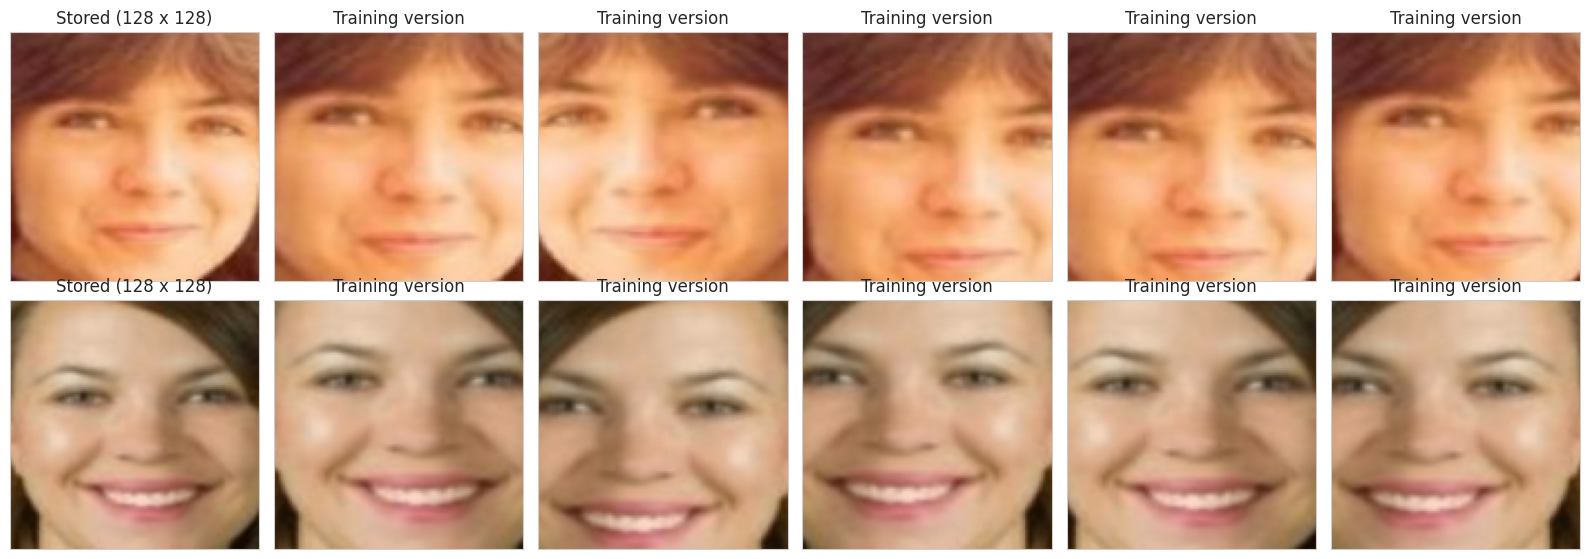

In [11]:
# Two training photographs, each passed five times through the training mode
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for row in range(2):
    axes[row][0].imshow(x_train[row])
    axes[row][0].set_title('Stored (128 x 128)')
    for ax in axes[row][1:]:
        ax.imshow(preprocess(x_train[row:row + 1], mode='train')[0])
        ax.set_title('Training version')
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Each row starts with a stored training photograph and continues with five
versions of it produced by the training mode, which is what the network may
receive in its place on five different epochs.

The crop removes a thin band of the frame and moves the face a few pixels, and
the flip mirrors it, as the position of the hair in the first row shows. None of these versions changes who the person is or
how the picture was taken, so the label stays right, which is the condition that
makes these changes safe to use.

## Machine Learning Model (CRISP-DM 4: Modeling)

The network is a CNN of four convolutional blocks followed by global average
pooling and a single output neuron. A convolutional block is the package of a
convolution, which slides its kernels over the input and produces feature maps,
the ReLU activation, which turns every negative value into zero, and max pooling,
which shrinks each feature map by keeping only the largest number of every
2 x 2 square. Pooling has no weights, so it learns nothing, it only summarises.

Dropout switches off a random half of the outputs of a layer at every training
step, so no neuron can rely on one particular partner, which works against
overfitting. The model is built in steps below, checking the shape of what comes
out after each one.

In [12]:
# The convolutional part: four blocks of 3 x 3 kernels, 32, 64, 128 and 256 of them
input_shape = (IMAGE_SIZE[1], IMAGE_SIZE[0], CHANNELS)
beauty_cnn = keras.Sequential([
    keras.Input(shape=input_shape),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu', name='conv_1'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(rate=DROPOUT_RATE),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu', name='conv_2'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(rate=DROPOUT_RATE),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu', name='conv_3'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu', name='conv_4'),
], name='beauty_cnn')

print('Output of the convolutional part:', beauty_cnn.output_shape)

Output of the convolutional part: (None, 14, 14, 256)


The shape reads as photographs in the batch, height, width and feature maps,
with None standing for a batch of any size. The padding called same adds a border
of zeros so each convolution keeps the size of its input, and each of the three
max poolings halves it, from 112 to 56, 28 and 14, so the last convolution leaves
256 feature maps of 14 by 14 for every photograph.

In [13]:
# Global average pooling turns each of the 256 feature maps into its average
beauty_cnn.add(layers.GlobalAveragePooling2D())
print('Output after global average pooling:', beauty_cnn.output_shape)

Output after global average pooling: (None, 256)


Global average pooling replaces each feature map by a single number, its
average, so each photograph is now described by 256 numbers instead of
14 x 14 x 256 = 50176. The output neuron added next receives those 256 numbers.

In [14]:
# One output neuron with no activation, so it returns a logit
beauty_cnn.add(layers.Dense(1, activation=None))
beauty_cnn.summary()

Model: "beauty_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 112, 112, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,673 (1.48 MB)

 Trainable params: 388,673 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

The last layer has no activation and returns a logit, a number of any size that
becomes a probability once it passes through the sigmoid function. A logit of 0
is a probability of 0.5, a positive logit means more likely a professional model
and a negative one more likely a common person.

The summary lists the layers in order. For each one, the output shape says what
leaves it and the parameter count says how many weights it learns. A convolution
of 3 x 3 kernels learns 3 x 3 x input channels weights plus one bias per kernel,
so the first one has 3 x 3 x 3 x 32 + 32 = 896, and the output neuron has 256
weights plus one bias, 257. The pooling and dropout layers show 0 parameters
because they learn nothing.

The network learns 388673 numbers in total, all of them trainable. The last
convolution alone holds 295168 of them, three quarters of the total, because it
has the most kernels and each one spans the 128 maps that enter it. The output
neuron needs only 257 thanks to global average pooling. Flattening the
14 x 14 x 256 maps instead would have given it 50177.

The weights are fitted with the Adam optimizer and a learning rate of 0.001, the
size of the step the weights take at every update, which is the default value of
Adam. A step much larger makes the weights jump from one side of the minimum to
the other without settling, and both curves stall together.

The validation accuracy does not climb in a straight line, it goes up and down
from one epoch to the next, and when training ends the network keeps the weights
of the last epoch, which need not be the best ones. A checkpoint solves that. It
is a copy of the weights saved to disk during training, and the ModelCheckpoint
callback, a function Keras calls on its own at the end of every epoch, saves it
only when the validation accuracy beats the best value seen so far. A tie does
not count as an improvement, so the file keeps the first epoch that reached the
best value.

In [15]:
# Binary cross-entropy computed from the logits, Adam optimizer with its step
# size, and accuracy
# read with the logit threshold of 0
beauty_cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                   loss=keras.losses.BinaryCrossentropy(from_logits=True),
                   metrics=[keras.metrics.BinaryAccuracy(name='accuracy',
                                                         threshold=LOGIT_THRESHOLD)])

# Keep the weights of the epoch with the best validation accuracy
checkpoint = keras.callbacks.ModelCheckpoint(CHECKPOINT_FILE,
                                             monitor='val_accuracy', mode='max',
                                             save_best_only=True,
                                             save_weights_only=True)

start = time.time()
history = beauty_cnn.fit(ds_train,
                         validation_data=ds_valid,
                         epochs=EPOCHS,
                         callbacks=[checkpoint],
                         verbose=2)
print('Training took %.1f minutes.' % ((time.time() - start) / 60))

Epoch 1/30
125/125 - 15s - 124ms/step - accuracy: 0.5677 - loss: 0.6732 - val_accuracy: 0.6233 - val_loss: 0.6342
Epoch 2/30
125/125 - 9s - 72ms/step - accuracy: 0.7065 - loss: 0.5718 - val_accuracy: 0.7467 - val_loss: 0.5095
Epoch 3/30
125/125 - 3s - 21ms/step - accuracy: 0.7765 - loss: 0.4939 - val_accuracy: 0.8067 - val_loss: 0.4742
Epoch 4/30
125/125 - 5s - 39ms/step - accuracy: 0.7955 - loss: 0.4520 - val_accuracy: 0.7567 - val_loss: 0.5264
Epoch 5/30
125/125 - 2s - 19ms/step - accuracy: 0.8085 - loss: 0.4404 - val_accuracy: 0.8333 - val_loss: 0.4165
Epoch 6/30
125/125 - 2s - 19ms/step - accuracy: 0.8150 - loss: 0.4178 - val_accuracy: 0.7800 - val_loss: 0.4825
Epoch 7/30
125/125 - 3s - 21ms/step - accuracy: 0.8367 - loss: 0.3908 - val_accuracy: 0.8067 - val_loss: 0.4333
Epoch 8/30
125/125 - 2s - 20ms/step - accuracy: 0.8380 - loss: 0.3924 - val_accuracy: 0.8533 - val_loss: 0.3587
Epoch 9/30
125/125 - 2s - 19ms/step - accuracy: 0.8543 - loss: 0.3594 - val_accuracy: 0.8200 - val_los

Each line is one epoch. The loss is the binary cross-entropy, the average
penalty for the probabilities given to the correct class, which is near 0 when
the network gives the right class a probability close to 1 and grows fast when
it is confident and wrong. The accuracy is the share of photographs classified
correctly. The columns without a prefix are measured on the training photographs
during the epoch, and the ones that start with val are measured afterwards on the
validation photographs.

The network starts at 0.6233 of validation accuracy after the first epoch, passes
0.80 at the third and reaches 0.90 for the first time at epoch 23. By epoch 30 it
is at 0.9190 on training and 0.9267 on validation, with losses of 0.2091 and
0.1773. The first epoch takes longer than the rest because the computation is
prepared the first time it runs.

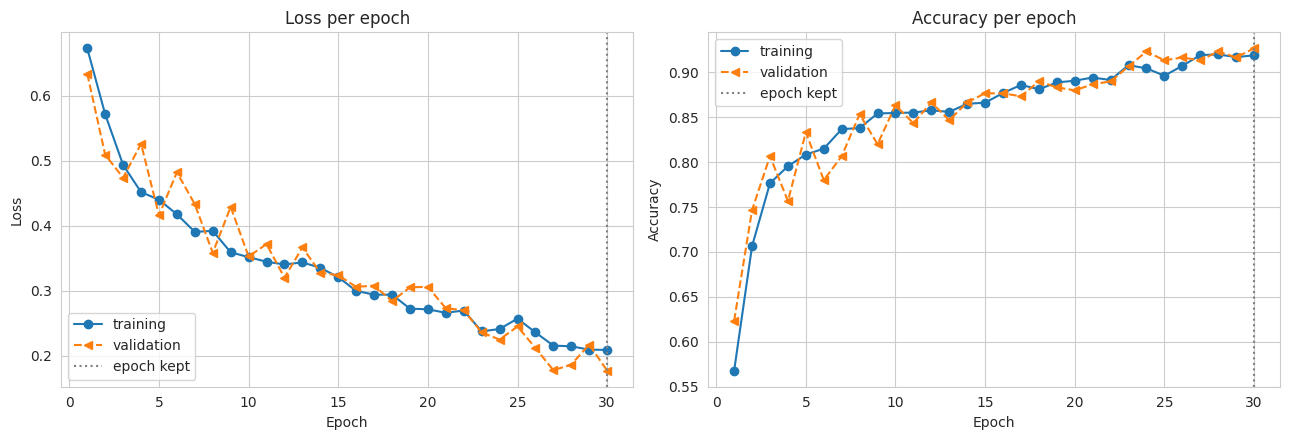

Epoch kept by the checkpoint: 30
Validation accuracy at that epoch: 0.9267
Validation accuracy at the last epoch: 0.9267


In [16]:
# Loss and accuracy of every epoch, with the epoch the checkpoint kept marked
records = history.history
epochs = np.arange(1, len(records['loss']) + 1)
best_epoch = int(np.argmax(records['val_accuracy'])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(epochs, records[metric], '-o', label='training')
    ax.plot(epochs, records['val_' + metric], '--<', label='validation')
    ax.axvline(best_epoch, color='grey', linestyle=':', label='epoch kept')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.capitalize())
    ax.set_title(metric.capitalize() + ' per epoch')
    ax.legend()
plt.tight_layout()
plt.show()

print('Epoch kept by the checkpoint:', best_epoch)
print('Validation accuracy at that epoch: %.4f' % records['val_accuracy'][best_epoch - 1])
print('Validation accuracy at the last epoch: %.4f' % records['val_accuracy'][-1])

The left panel draws the loss of every epoch and the right one the accuracy, in
blue on the training photographs and in orange on the validation ones, and the
dotted grey line marks the epoch the checkpoint kept. Falling loss and rising
accuracy mean the network is still learning. The distance between the two curves
is what tells the two problems apart. Training high and validation low, with a
wide gap, is overfitting, the network memorising the training pictures, which is
high variance. Both curves low and close together is high bias, a network that
cannot capture the pattern at all. A validation score better than the training
one is not an error here: during training half the outputs of two layers are
switched off by dropout and the photographs are randomly cropped and flipped,
while validation uses the whole network on the central crop.

Both curves fall and rise together through the 30 epochs, and validation is above
training in 15 of them, half, so there is no sign of overfitting. There is no sign
of high bias either, since both accuracies end above 0.91. The validation curve is
jumpier in the first ten epochs, with drops to 0.7567 at epoch 4, 0.7800 at epoch
6 and 0.8200 at epoch 9, which is what 300 photographs give, since one picture
moves the accuracy by a third of a point. The best validation accuracy, 0.9267,
and the lowest validation loss, 0.1773, both come at the last epoch, so the
checkpoint kept epoch 30 and the network it saved is the final one. That also
means the curves had not flattened yet: the training loss was still falling,
from 0.2663 at epoch 21 to 0.2091 at epoch 30, and a few more epochs could still
help.

In [17]:
# The network goes back to the weights of the best epoch
beauty_cnn.load_weights(CHECKPOINT_FILE)
_, kept_valid_accuracy = beauty_cnn.evaluate(preprocess(x_valid, mode='eval'),
                                             y_valid.astype(np.float32),
                                             batch_size=BATCH_SIZE, verbose=0)
print('Validation accuracy after loading the checkpoint: %.4f' % kept_valid_accuracy)

Validation accuracy after loading the checkpoint: 0.9267


Loading the checkpoint replaces the weights of the last epoch with those of the
epoch it kept, and measuring the validation part again confirms that the network
now in memory is that one.

The validation accuracy measured after loading is 0.9267, the same as epoch 30,
so the network evaluated from here on is the one the checkpoint saved.

## Evaluation (CRISP-DM 5)

The test photographs have not been seen by the network nor used to decide
anything about it, not even which epoch to keep, so their scores are the
estimate of how it would do on new faces.

In [18]:
# The test photographs get the central crop, the same as validation
x_test_ready = preprocess(x_test, mode='eval')

# Logits of the test photographs, turned into probabilities and classes
test_logits = beauty_cnn.predict(x_test_ready, batch_size=BATCH_SIZE, verbose=0).ravel()
test_probability = expit(test_logits)
test_predicted = (test_logits > LOGIT_THRESHOLD).astype(int)

test_loss, _ = beauty_cnn.evaluate(x_test_ready, y_test.astype(np.float32),
                                   batch_size=BATCH_SIZE, verbose=0)
majority_share = max(y_test.mean(), 1 - y_test.mean())
print('Test loss:     %.4f' % test_loss)
print('Test accuracy: %.4f' % accuracy_score(y_test, test_predicted))
print('Accuracy of always answering the larger class: %.4f' % majority_share)
print()
print(classification_report(y_test, test_predicted, target_names=CLASS_NAMES,
                            digits=4))

Test loss:     0.0940
Test accuracy: 0.9767
Accuracy of always answering the larger class: 0.5000

                    precision    recall  f1-score   support

     common person     0.9799    0.9733    0.9766       150
professional model     0.9735    0.9800    0.9767       150

          accuracy                         0.9767       300
         macro avg     0.9767    0.9767    0.9767       300
      weighted avg     0.9767    0.9767    0.9767       300



The accuracy is the share of test photographs classified correctly, and the line
below it is the floor any model has to beat: the accuracy of always answering the
larger class without looking at the picture. In the report, precision is, of the
photographs the network put in a class, the share that truly belong to it.
Recall is, of the photographs that truly belong to a class, the share the network
found. The f1-score combines both into one number, and support is how many test
photographs each class has.

The network classifies 97.67 percent of the test photographs correctly, against
50.00 percent for the floor and 83.33 percent for the logistic regression on the
three picture traits, and its test loss is 0.0940. The two classes are handled
almost equally. It finds 97.33 percent of the common people and 98.00 percent of
the models, and when it says model it is right 97.35 percent of the time.

The test score is higher than the validation score, 0.9767 against 0.9267. The
gap is 5 points, which on 300 photographs is 15 pictures, so the test part
happened to be easier. Neither number is the exact truth. With 300 photographs a
second sample of the same kind could land a few points away, and the 97.67
percent should be read with that margin in mind.

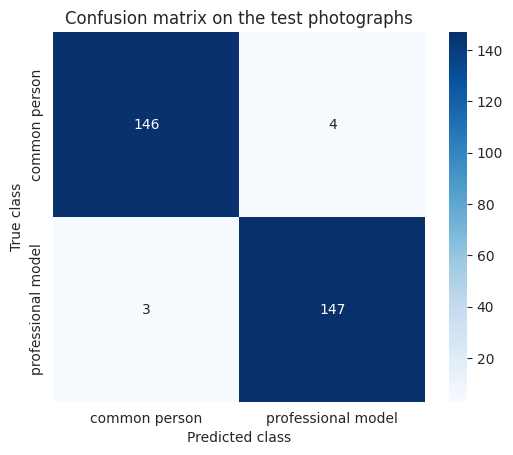

In [19]:
# Confusion matrix of the test photographs
matrix = confusion_matrix(y_test, test_predicted)
plt.figure(figsize=(6, 4.8))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Confusion matrix on the test photographs')
plt.show()

Each row of the matrix is a true class and each column a predicted one, so the
diagonal holds the correct answers and the two cells off it the two kinds of
mistake. The top right cell counts common people taken as models, the ones that
would reach the casting team without belonging there, and the bottom left one
counts models taken as common people, the ones the filter would throw away.

Of the 300 test photographs, 146 common people and 147 models are right. Of the
7 mistakes, 4 are common people taken as models, 2.7 percent of the 150, and 3
are models taken as common people, 2.0 percent. For a first filter in front of a
casting team the second kind is the costly one, since a candidate the team would
have wanted never reaches them, and it is also the rarer of the two here.

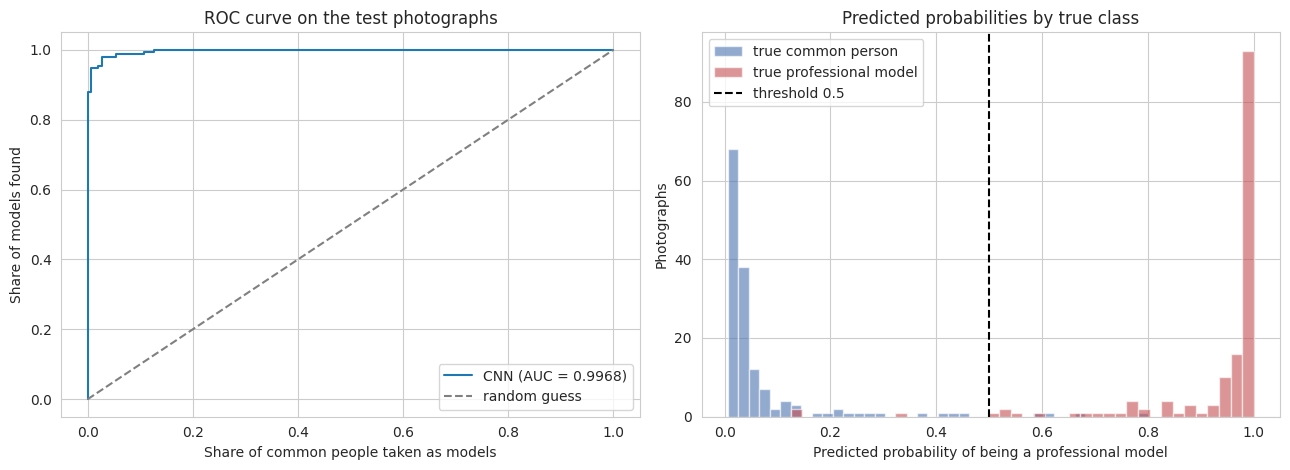

Area under the ROC curve: 0.9968


In [20]:
# ROC curve and the distribution of the predicted probabilities
false_rate, true_rate, _ = roc_curve(y_test, test_probability)
auc = roc_auc_score(y_test, test_probability)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(false_rate, true_rate, label='CNN (AUC = %.4f)' % auc)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='random guess')
axes[0].set_xlabel('Share of common people taken as models')
axes[0].set_ylabel('Share of models found')
axes[0].set_title('ROC curve on the test photographs')
axes[0].legend()

for label, colour in zip([0, 1], CLASS_COLOURS):
    axes[1].hist(test_probability[y_test == label], bins=40, alpha=0.6,
                 color=colour, label='true ' + CLASS_NAMES[label])
axes[1].axvline(0.5, color='black', linestyle='--', label='threshold 0.5')
axes[1].set_xlabel('Predicted probability of being a professional model')
axes[1].set_ylabel('Photographs')
axes[1].set_title('Predicted probabilities by true class')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Area under the ROC curve: %.4f' % auc)

The ROC curve moves the threshold from 1 down to 0 and draws, for each value, the
share of models found against the share of common people wrongly taken as models.
A perfect model goes straight up to the top left corner and the dashed diagonal
is a coin toss. The area under the curve, AUC, sums it up in one number from 0.5
for a coin toss to 1 for a perfect separation, and it can be read as the chance
that a random model gets a higher probability than a random common person. The
histogram shows the predicted probability of every test photograph, coloured by
its true class, with the threshold of 0.5 as a dashed line. Bars far from the
line are confident answers, and bars of one colour on the wrong side of the line
are the mistakes.

The curve climbs almost straight to the top left corner and the area under it is
0.9968, so in more than 99 of 100 pairs of one model and one common person the
model gets the higher probability. The histogram shows why. Most common people
pile up below 0.1 and most models above 0.9, with the tallest bar, more than 90
models, right at 1. Between the two piles only a thin trail of photographs runs
across the middle, and that is where the threshold of 0.5 decides and where most
of the 7 mistakes sit.

In [21]:
# The photographs where the picture traits point the wrong way are the ones the
# network cannot solve by sharpness or colour alone
trait_wrong = trait_test_predicted != y_test
for name, mask in [('traits right', ~trait_wrong), ('traits wrong', trait_wrong)]:
    print('%-13s %3d photographs, CNN accuracy %.4f'
          % (name, mask.sum(), accuracy_score(y_test[mask], test_predicted[mask])))

traits right  250 photographs, CNN accuracy 0.9840
traits wrong   50 photographs, CNN accuracy 0.9400


The test photographs are split in two groups by the answer of the trait
classifier from the exploration: the ones it got right, where sharpness and
colour already point to the true class, and the ones it got wrong, where the
picture looks like the other class. For each group the line gives how many
photographs it holds and the accuracy of the CNN on them. If the network leaned
only on the same traits, its accuracy on the second group would fall as low as
the trait classifier's, which is zero there by construction.

On the 250 test photographs where the picture traits already point to the right
class the CNN is right 98.40 percent of the time. On the 50 where they point the
wrong way, sharp snapshots of common people and soft portraits of models, it is
still right 94.00 percent of the time, 47 of the 50. So the network is not a
sharpness meter: it finds the class in almost all the pictures where sharpness
and colour would mislead it. But those pictures are still harder for it. Its
accuracy drops by 4.4 points, and 3 of its 7 mistakes fall in that group, which
holds only one test photograph in six.

Wrong answers: 7 of 300


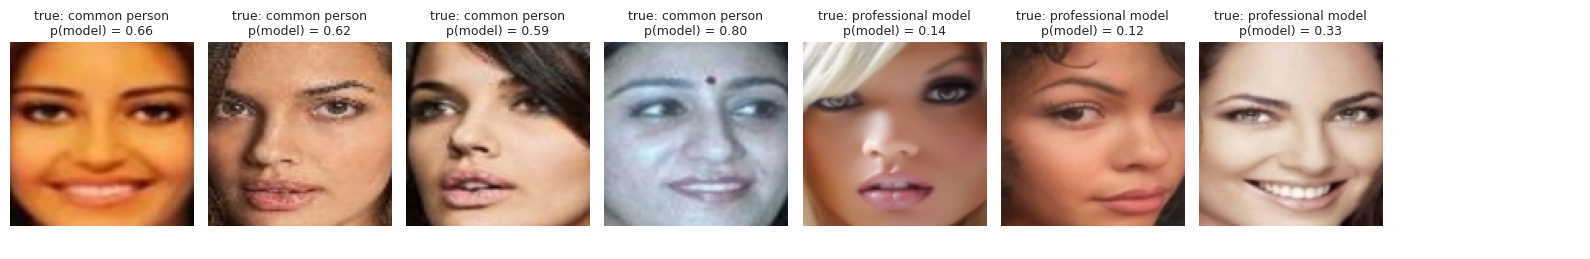

In [22]:
# The test photographs the network got wrong, with the probability it gave
wrong = np.flatnonzero(test_predicted != y_test)
print('Wrong answers:', len(wrong), 'of', len(y_test))

shown = wrong[:16]
if len(shown) > 0:
    columns = 8
    rows = int(np.ceil(len(shown) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(16, 2.6 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, position in zip(axes.ravel(), shown):
        ax.imshow(x_test_ready[position])
        ax.set_title('true: %s\np(model) = %.2f'
                     % (CLASS_NAMES[y_test[position]], test_probability[position]),
                     fontsize=9)
    plt.tight_layout()
    plt.show()

Each picture is a test photograph the network classified wrongly, at the size it
saw it, with its true class and the probability of being a professional model the
network gave it. A probability near 0.5 is a doubtful case, and one near 0 or 1
is a confident mistake.

All 7 mistakes are shown. Four of them are doubtful cases, with a probability
between 0.33 and 0.66, and three are confident ones. Two of the common people
taken as models, the freckled face at 0.62 and the dark-haired woman with parted
lips at 0.59, are sharp close-ups with defined eyebrows and lips that look like
portraits. The models taken as common people are soft, evenly lit pictures with
little contrast, such as the platinum blonde at 0.14 and the model with a natural
look and no visible make-up at 0.12, the two confident mistakes on that side, or
the smiling model at 0.33, whose wide smile resembles the snapshots. Most of the
mistakes fit the same reading: when the picture looks like the other class, the
network follows the picture. Not all of them do. The first common person, at
0.66, is a soft, warm and blurred picture, the kind of snapshot the network
usually gets right, and the third confident mistake, a common person with a bindi
under bluish light at 0.80, has no obvious trait of a portrait either.

### What the network learned

The scores say how often the network is right, not why. Two views of the trained
network answer that. The first draws the filters of the first convolution, the
patterns it learned to look for. The second draws the activation maps, the
feature maps a layer produces for one particular photograph, which show where in
that photograph each filter found its pattern.

Shape of the filter weights: (3, 3, 3, 32)


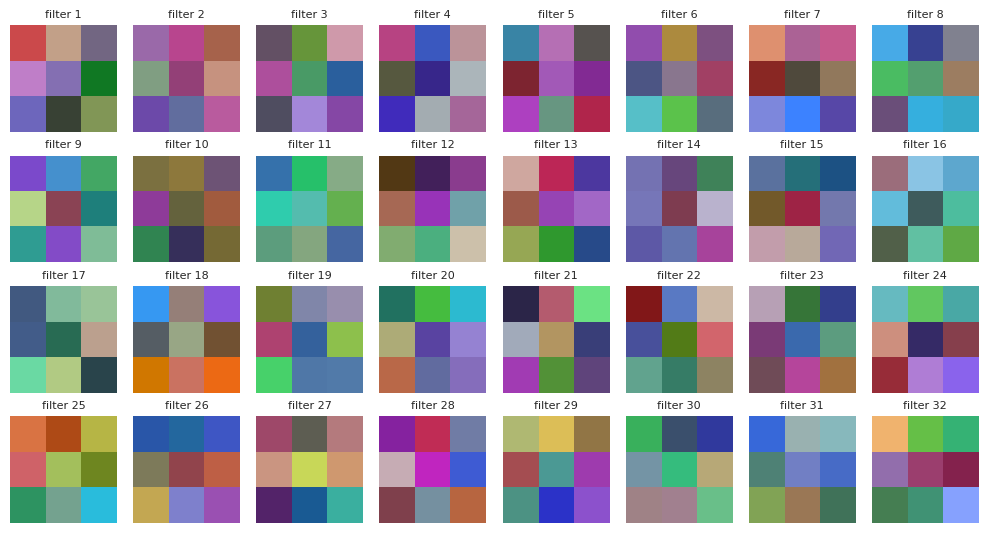

In [23]:
# The 32 filters of the first convolution, each one as a small colour picture,
# after scaling all the weights of the layer to the range 0 to 1
filters, _ = beauty_cnn.get_layer('conv_1').get_weights()
scaled = (filters - filters.min()) / (filters.max() - filters.min())
print('Shape of the filter weights:', filters.shape)

fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(scaled[:, :, :, index])
    ax.set_title('filter %d' % (index + 1), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

The weights of the first convolution have the shape height, width, input
channels and number of filter: 32 filters of 3 x 3 over the 3 colour channels.
Weights can be negative and a picture cannot, so all of them are scaled together
to the range 0 to 1 before drawing, and each filter is drawn as a 3 by 3 colour
picture whose red, green and blue come from its three channels. A filter with a
light side next to a dark side is an edge detector, one with a single dominant
colour reacts to that colour, and one that looks like flat grey is weak or
reacts to brightness alone. Only the first layer can be read this way, since it
works directly on pixels, while deeper layers combine feature maps and look like
noise when drawn.

The filters do not look like neat edge detectors with a light side and a dark
side. Most of them are mixtures of colours, magenta next to green, blue next to
brown, so at this first step the network looks mainly at combinations of colour
and at the changes from one colour to another. That fits a problem where skin
tone, lipstick and make-up around the eyes are part of what separates the two
classes. A few filters, such as 12 and 17, have a dark column or row against a
lighter one, which is the pattern of an edge.

common person: maps of (56, 56, 64), 8 of 64 entirely zero
professional model: maps of (56, 56, 64), 8 of 64 entirely zero


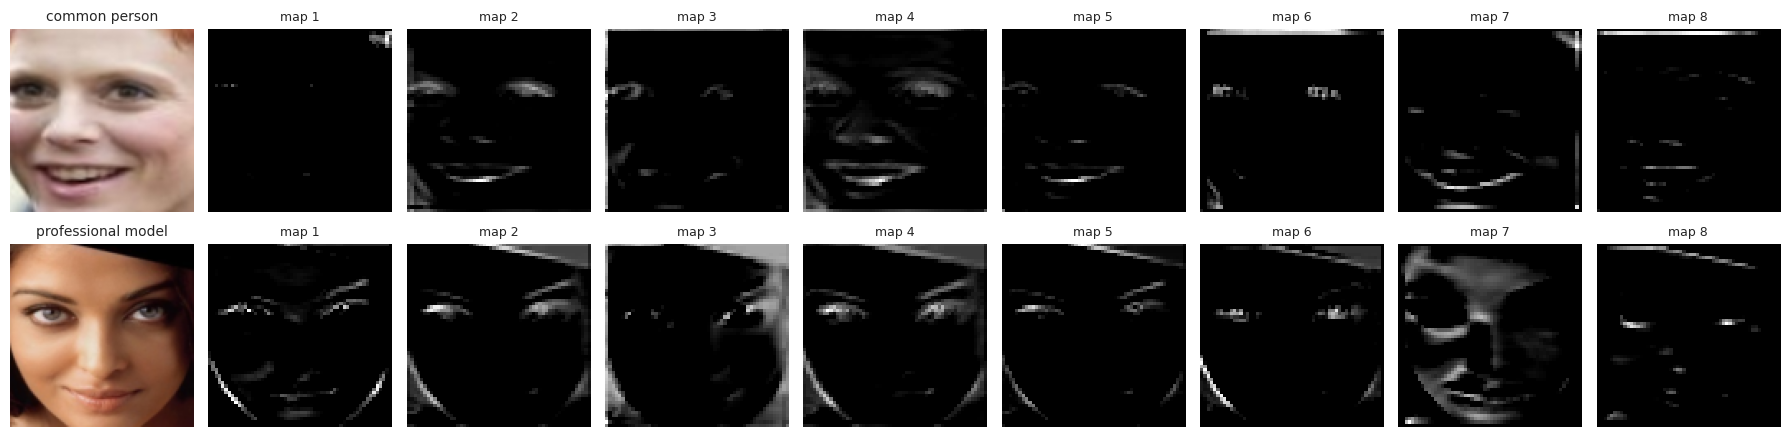

In [24]:
# A second model that shares the trained weights but stops after a convolution
def activation_maps(model, layer_name, image):
    """Feature maps that one layer produces for a single prepared photograph."""
    cut = keras.Model(inputs=model.inputs, outputs=model.get_layer(layer_name).output)
    return keras.ops.convert_to_numpy(cut([image[np.newaxis]], training=False))[0]


# One test photograph of each class and the first 8 maps of the second convolution
fig, axes = plt.subplots(2, 9, figsize=(18, 4.6))
for row, label in enumerate([0, 1]):
    position = np.flatnonzero(y_test == label)[0]
    maps = activation_maps(beauty_cnn, 'conv_2', x_test_ready[position])
    axes[row][0].imshow(x_test_ready[position])
    axes[row][0].set_title(CLASS_NAMES[label], fontsize=10)
    for index, ax in enumerate(axes[row][1:]):
        ax.imshow(maps[:, :, index], cmap='gray')
        ax.set_title('map %d' % (index + 1), fontsize=9)
    print('%s: maps of %s, %d of %d entirely zero'
          % (CLASS_NAMES[label], maps.shape, (maps.max(axis=(0, 1)) == 0).sum(), maps.shape[2]))
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

To get the maps, a second model is built that shares the weights of the trained
one but ends at the second convolution, so nothing is trained again. Each row
starts with a test photograph and continues with the first eight of its 64 maps
of 56 by 56. Black is zero and white is the highest value of that map, and each
map is scaled on its own, so two whites in different maps do not mean the same
amount. A map that is black everywhere is one the ReLU set to zero because the
filter did not find its pattern in this photograph. The printed lines count how
many of the 64 maps are entirely zero for each photograph. What matters is where
the bright zones fall: on the eyes, the mouth and the outline of the face, or on
the background and the borders of the picture.

For both photographs 8 of the 64 maps are entirely zero, so a few filters find
nothing in either face. The maps that are lit follow the face. For the model,
maps 1, 2, 4, 5 and 6 light up the eyes and the outline of the jaw, the same
outline the difference between the averages pointed to, and map 7 the whole skin
of the face. For the common person, maps 2, 4 and 5 light up the eyebrows and the
line of the lips. There are two warning signs. For the common person, maps 6 and 8
light a thin line along the top edge of the frame, which is the border of the
picture, not the person, because the padding of zeros makes the edge look like a
contrast for some filters. For the model, maps 2 and 3 light up the brim of the
hat in the top right corner, which is background. They are small zones, but they
mean the network can pick up traits of the frame and the background too.

## Results (CRISP-DM 6: Deployment)

The trained network is saved to a file and loaded back, the way it would be
deployed in the tool that sorts the portraits, and the loaded copy classifies
photographs read straight from disk. The photographs come from the test folders,
so the network never trained on them.

Saved and reloaded beauty_cnn.keras (4.5 MB)
beauty/test/average/074.jpg -> common person with p(model) = 0.0326
beauty/test/beautiful/074.jpg -> professional model with p(model) = 0.9553


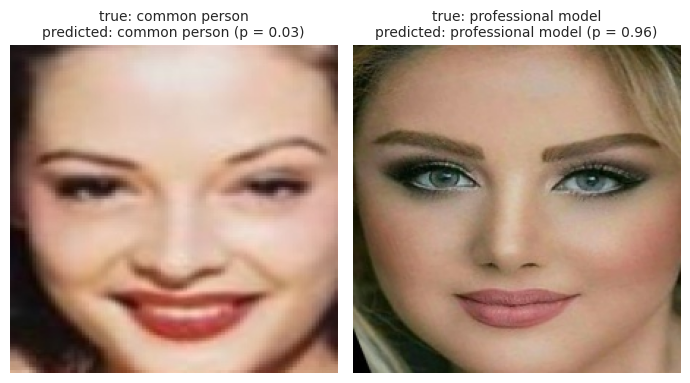

In [25]:
# Save the trained network and load it back
beauty_cnn.save(MODEL_FILE)
loaded_cnn = keras.models.load_model(MODEL_FILE)
print('Saved and reloaded', MODEL_FILE,
      '(%.1f MB)' % (os.path.getsize(MODEL_FILE) / 1024 ** 2))


# Classify one file with the loaded network
def predict_group(path, model):
    """Return the predicted class and the probability of being a model."""
    batch = preprocess(load_image(path)[np.newaxis], mode='eval')
    logit = float(keras.ops.convert_to_numpy(model(batch, training=False))[0, 0])
    probability = float(expit(logit))
    return CLASS_NAMES[int(logit > LOGIT_THRESHOLD)], probability


# One test photograph of each class, read from its file
test_faces = faces[faces['split'] == 'test']
fig, axes = plt.subplots(1, 2, figsize=(7, 4))
for ax, folder in zip(axes, CLASS_FOLDERS):
    path = test_faces[test_faces['folder'] == folder].sample(
        1, random_state=RANDOM_STATE)['path'].iloc[0]
    predicted, probability = predict_group(path, loaded_cnn)
    with Image.open(path) as handle:
        ax.imshow(handle.convert('RGB'))
    ax.set_title('true: %s\npredicted: %s (p = %.2f)'
                 % (CLASS_NAMES[CLASS_FOLDERS[folder]], predicted, probability),
                 fontsize=10)
    ax.axis('off')
    print(path, '->', predicted, 'with p(model) = %.4f' % probability)
plt.tight_layout()
plt.show()

The size printed is the file that would be copied to the sorting tool, and each
picture is shown at its original size with its true class and the answer of the
reloaded network.

The saved network takes 4.5 MB and the copy loaded back from disk works. It gives
the common person a probability of being a model of 0.0326 and the model 0.9553,
both on the right side of 0.5 and both confident. Both look like the typical
picture of their class, a blurred snapshot and a sharp portrait with heavy
make-up, so they are not the hard cases the mistakes above showed. The cell
checks that the saved model loads and predicts, and the evaluation of how well
it predicts is the test section above.

### Conclusions

The model is a convolutional neural network of four convolutional blocks with
32, 64, 128 and 256 kernels of 3 x 3, max pooling, dropout and global average
pooling, ending in a single neuron that gives the logit of being a professional
model. It learns 388673 parameters from 4000 photographs, with random crops and
flips as data augmentation, over 30 epochs with the Adam optimizer at a learning
rate of 0.001, and a checkpoint that keeps the epoch with the best validation
accuracy.

On 300 test photographs it never saw it is right 97.67 percent of the time,
against 50.00 percent for always giving the same answer, and its area under the
ROC curve is 0.9968. It passes 4 of 150 common people as models and discards 3
of 150 models. Training and validation curves rose together with no sign of
overfitting, and the best epoch was the last one, so the network had not
finished improving.

The photographs themselves carry a large part of the answer. Sharpness, colour
and brightness alone, with no face involved, already give 83.33 percent, because
the model portraits are much sharper than the snapshots of common people. The
CNN goes well beyond that: on the 50 test photographs where those traits point
the wrong way it is still right 94.00 percent of the time. But 3 of its 7
mistakes are in that group, which holds one test photograph in six, most of its
mistakes are sharp snapshots taken as portraits and soft portraits taken as
snapshots, and its activation maps light up the border of the frame and the
background as well as the face. The network has learned the face and the way
the picture was taken together, and the data does not allow separating one from
the other.

Its use is recommended only as a first sorting step, for example to order a pile
of applications so a person looks at the most likely candidates first, and never
to discard anyone on its own. Its limitations follow from the data. The
validation and test parts have 300 photographs each, so its accuracy is known
only to within a few points, as the 5 point gap between them shows. All the
photographs are close-ups of women facing the camera, so it says nothing about
men, profiles or full-body shots. And because the models come from professional
shoots and the common people from everyday photographs, a portrait of a common
person taken by a professional photographer, or a snapshot of a model, is
exactly the case it is most likely to get wrong. A test on photographs from a
new source, taken under the same conditions for both groups, is needed before
trusting it to judge the person rather than the camera.